# API 8: Regularization

Regularization helps interpretability by making KANs sparser. This may require some hyperparamter tuning. Let's see how hyperparameters can affect training

Load KAN and create_dataset

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
train['x'].shape, train['y'].shape

cuda


(torch.Size([1000, 2]), torch.Size([1000, 1]))

We apply L1 regularization to which tensor? Currently, we support five choices for reg_metric:
* 'edge_forward_spline_n': the "norm" of edge, normalized (output std/input std), only consider the spline (ignorning symbolic)
* 'edge_forward_sum': the "norm" of edge, normamlized (output std/input std), including both spline + symbolic
* 'edge_forward_spline_u': the "norm" of edge, unnormalized (output std), only consider the spline (ignorning symbolic)
* 'edge_backward': edge attribution score
* 'node_backward': node attribution score

train RMSE 0.051758365808084544 test RMSE 0.049793690982140586


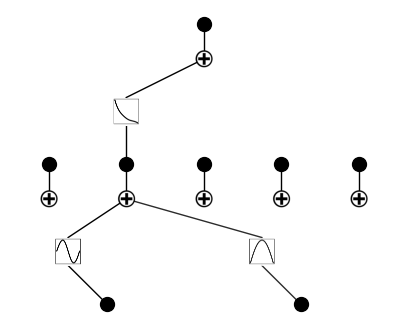

In [2]:
# train the model
model = KANNetwork([2,5,1], grid=3, k=3, seed=1, device=device)
history = fit(model, train, test, steps=20, lamb=0.01, reg_metric='edge_forward_spline_n') # default
#history = fit(model, train, test, steps=20, lamb=0.01, reg_metric='edge_forward_sum')
#history = fit(model, train, test, steps=20, lamb=0.01, reg_metric='edge_forward_spline_u')
#history = fit(model, train, test, steps=20, lamb=0.01, reg_metric='edge_backward')
#history = fit(model, train, test, steps=20, lamb=0.01, reg_metric='node_backward')
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x']);

Note: To plot the KAN diagram, there are also three options
* forward_u: same as edge_forward_spline_u
* forward_n: same as edge_forward_spline_u
* backward: same as edge_backward

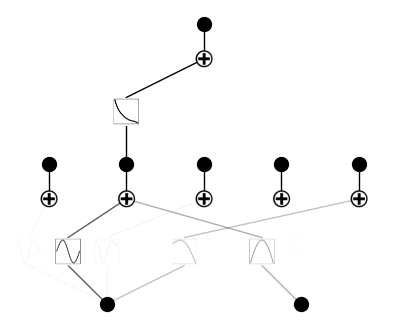

In [3]:
plot(model, train['x'], metric='forward_u');
#plot(model, train['x'], metric='forward_n');
#plot(model, train['x'], metric='backward'); # default